# Segment review

* 시점: holdout 평가 이후 사후 탐색
* 확인: 고객군별 관측 구매율 차이, 최종 모델 점수의 SHAP 기여도
* 해석 범위: 변수별 원인·확정 발송 규칙 아님

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
candidates = [p for base in (Path.cwd(), *Path.cwd().parents) for p in (base, base / "code")]
CODE = next(p for p in candidates if (p / "evidence").is_dir() and (p / "modeling").is_dir())
PROJECT = CODE.parent

ROWS = (
    ("category_count", "구매 카테고리 수: 10개 이하 vs 15개 이상", -1, "견고"),
    ("spend_90d", "90일 구매액: 3,212 이하 vs 7,161 초과", -1, "조건부"),
    ("purchases_90d", "90일 구매 횟수: 8회 이하 vs 18회 이상", -1, "조건부"),
    ("days_since_issue", "카드 발급 후: 368일 이하 vs 583일 초과", -1, "견고"),
    ("express_points_used", "익스프레스 포인트: 사용 vs 미사용", 1, "견고"),
    ("age", "나이: 65세 이상 vs 18–34세", 1, "약함"),
)
estimates = pd.read_csv(CODE / "evidence/post_subgroup/contrasts.csv").set_index("feature")
rows = []
for feature, label, sign, grade in ROWS:
    row = estimates.loc[feature]
    rows.append({"비교": label, "격차 (%p)": sign * row["diff_pp"], "검증 결과": grade})
display(pd.DataFrame(rows).round({"격차 (%p)": 2}))

,비교,격차 (%p),검증 결과
0,구매 카테고리 수: 10개 이하 vs 15개 이상,5.29,견고
1,"90일 구매액: 3,212 이하 vs 7,161 초과",4.29,조건부
2,90일 구매 횟수: 8회 이하 vs 18회 이상,3.63,조건부
3,카드 발급 후: 368일 이하 vs 583일 초과,2.95,견고
4,익스프레스 포인트: 사용 vs 미사용,2.79,견고
5,나이: 65세 이상 vs 18–34세,2.78,약함


## 사후 분석 실행 (선택)

* 순서: 점수 구간 → 고객군 비교 → 추가 검증 → SHAP·보조 지표
* 입력: holdout 평가까지 완료한 비공개 작업 폴더
* 실행 조건: `X5_WORK_DIR` 지정 후 `X5_RUN_FULL=1`


In [ ]:
import os
import subprocess
import sys

if os.environ.get("X5_RUN_FULL") == "1":
    assert os.environ.get("X5_WORK_DIR")
    work = Path(os.environ["X5_WORK_DIR"]).resolve()
    assert (work / "results/final/holdout_eval/holdout_predictions.parquet").is_file()
    tasks = [
        ("post_heterogeneity.py", []),
        ("post_subgroup.py", []),
        ("post_subgroup_limits.py", []),
        ("post_score_drivers.py", ["--fig", str(work / "figs/score_drivers.png")]),
        ("post_metric_check.py", []),
        ("report_baseline.py", []),
        ("report_supplement.py", []),
    ]
    for name, args in tasks:
        log = work / "logs" / f"{Path(name).stem}.log"
        log.parent.mkdir(parents=True, exist_ok=True)
        with log.open("w") as output:
            subprocess.run([sys.executable, str(work / "modeling" / name), *args],
                           cwd=work, stdout=output, stderr=subprocess.STDOUT, check=True)
        print(name, "완료 ·", log)
    local = pd.read_csv(work / "results/post_subgroup/contrasts.csv")
    display(local[["feature", "diff_pp"]].rename(columns={"diff_pp": "구매율 차이 격차 (%p)"}))
else:
    print("사후 분석 실행: 생략 · 저장된 고객군 결과 확인")


## 고객군 비교

* 격차: 앞 고객군의 관측 구매율 차이 − 뒤 고객군의 관측 구매율 차이
* 막대 끝 구간: 보정 전 95% 신뢰구간
* 색상: 다중비교·척도 변경·다른 변수 통제 결과를 종합한 판정

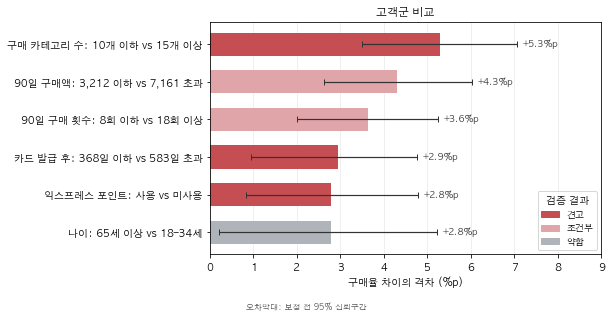

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

colors = {"견고": "#C44E52", "조건부": "#E0A5A8", "약함": "#AEB4BA"}
plt.rcParams["font.family"] = ["AppleGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
fig, ax = plt.subplots(figsize=(8.6, 4.4))
for y, (feature, label, sign, grade) in enumerate(ROWS):
    row = estimates.loc[feature]
    value = sign * row.diff_pp
    lo, hi = sorted((sign * row.ci_lo_pp, sign * row.ci_hi_pp))
    ax.barh(y, value, color=colors[grade], height=0.62)
    ax.errorbar(value, y, xerr=[[value - lo], [hi - value]], fmt="none",
                ecolor="#333333", capsize=3, lw=1.2)
    ax.text(hi + 0.12, y, f"{value:+.1f}%p", va="center", fontsize=9, color="#333333")
ax.set_yticks(range(len(ROWS)))
ax.set_yticklabels([row[1] for row in ROWS])
ax.invert_yaxis()
ax.set_xlim(0, 9)
ax.set_xlabel("구매율 차이의 격차 (%p)")
ax.set_title("고객군 비교", fontsize=11)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=colors[name], label=name) for name in colors],
          title="검증 결과", loc="lower right", fontsize=9)
fig.text(0.5, 0.01, "오차막대: 보정 전 95% 신뢰구간", ha="center", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, 0.045, 1, 1))
plt.show()

## 모델 점수에 대한 SHAP 기여도

* 지표: 최종 모델 점수에 대한 평균 절댓값 SHAP 비중
* 해석 범위: 점수 기여 크기; 구매 반응의 원인·영향 방향 아님

,비중 (%)
express_points_used,9.90
age,8.14
days_since_issue,6.66
spend_30d,4.64
product_lines,4.17
mean_red_amount,4.14
purchase_amount_cv,3.96
spend_per_purchase,3.57
median_netto,3.44
spend_90d,3.44


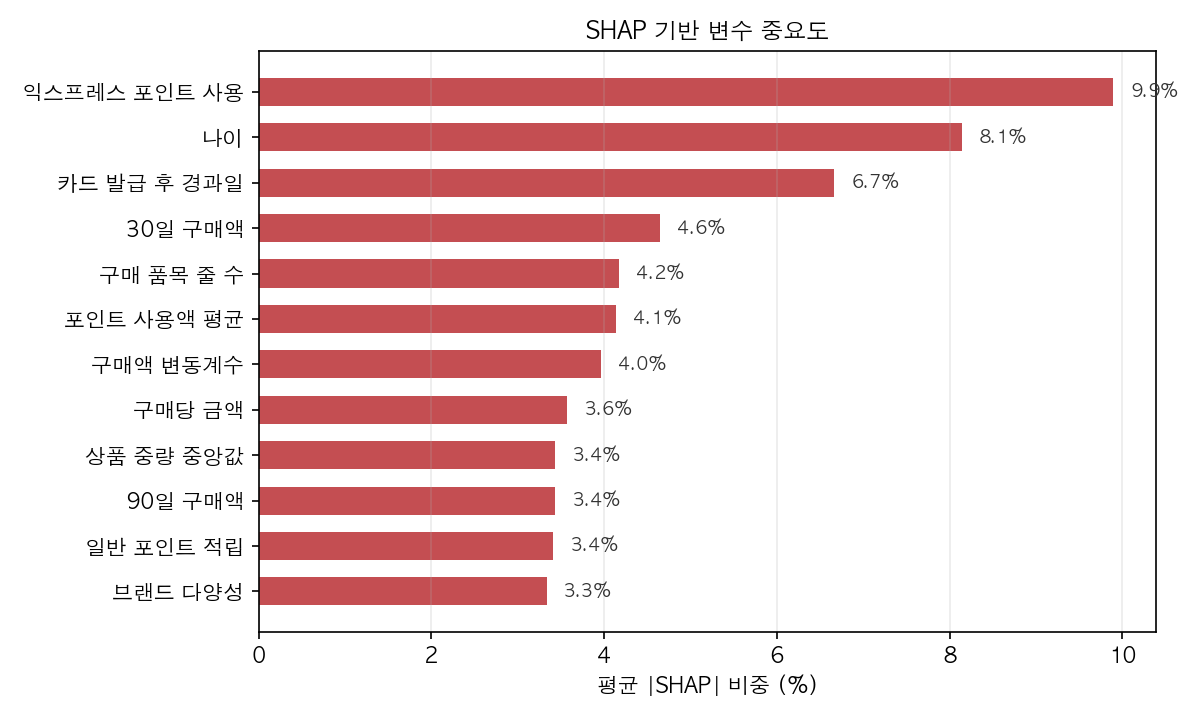

In [3]:
drivers = json.loads((CODE / "evidence/post_score_drivers/score_drivers.json").read_text())
shares = pd.Series(drivers["shap_share"], name="평균 |SHAP| 비중").sort_values(ascending=False)
display((100 * shares.head(12)).round(2).to_frame("비중 (%)"))
display(Image(filename=str(PROJECT / "figs/score_drivers.png")))